Análise de variações no MCTS:

In [26]:
!python --version

Python 3.11.15


In [1]:
#imports
from game import Game
from players import MCTS

In [28]:
#o método run do Game é mais para poder jogar no terminal com prints e assim
#notebook_run feito de proprósito para a análise
stats = Game("","").notebook_run("mcts_simplest", MCTS().move, "mcts_heuristic_win", MCTS(heuristic_win=True).move)
print(stats)

{'player1': 'mcts_simplest', 'player2': 'mcts_heuristic_win', 'winner': -1, 'winner_name': 'mcts_heuristic_win', 'time_player1': 2.941315856005531, 'time_player2': 1.7322501290473156, 'avg_time_player1': 0.24510965466712756, 'avg_time_player2': 0.14435417742060963}


In [ ]:
# "mcts_simplest":MCTS(child_limit=8,).move,
# "mcts_heuristic_win":MCTS(child_limit=8,heuristic_win=True).move, #selects win state during simulation
# "mcts_heuristic_block_win" : MCTS(child_limit=8,heuristic_block_win=True).move, #doesnt chose a move that lets the opponent win
# "mcts_win_and_block_win" : MCTS(child_limit=8,heuristic_win=True, heuristic_block_win=True).move,
# "mcts_tree":MCTS(child_limit=8,save_tree=True).move, #one of the above, but saving the tree
# "mcts_full" : MCTS(child_limit=8,heuristic_win=True, heuristic_block_win=True, save_tree=True).move,#block_win deixa muito lento
child_variants_300 = [
      ("all_300", MCTS(max_iter=300)),
      ("child_2_300", MCTS(child_limit=2, max_iter=300)),
      ("child_4_300", MCTS(child_limit=4, max_iter=300)),
      ("child_8_300", MCTS(child_limit=8, max_iter=300)),
]
# "mcts_select_8_children_more_iters" : MCTS(child_limit=8, max_iter=500).move,
# "mcts_select_all_children_more_iters" : MCTS(max_iter=500).move,

In [35]:
child_variants_300 = [
    ("all_300", MCTS(max_iter=300)),
    ("child_2_300", MCTS(child_limit=2, max_iter=300)),
    ("child_4_300", MCTS(child_limit=4, max_iter=300)),
    ("child_8_300", MCTS(child_limit=8, max_iter=300)),
]

In [2]:
#p1 vs p2 e p2 vs p1 se n_games=5 então corre-se 10 jogos no total entre eles
def variants_stats(variants, n_games=5):
    stats= {}
    for name, _ in variants:
        stats[name] = {
            "wins": 0,
            "draws": 0,
            "losses": 0,
            "avg_time_sum": 0 # sum of the avg times per move for all the games
        }

    for i in range(len(variants)):
        for j in range(i + 1, len(variants)):
            for (p1, mcts1), (p2, mcts2) in [(variants[i], variants[j]),(variants[j], variants[i])]:
                for _ in range(n_games):
                    #reset the root node of the tree
                    mcts1.root = None 
                    mcts2.root = None
                    res = Game("","").notebook_run(p1,mcts1.move,p2,mcts2.move)
                    
                    stats[p1]["avg_time_sum"] += res["avg_time_player1"]
                    stats[p2]["avg_time_sum"] += res["avg_time_player2"]

                    if res["winner"] == 1:
                        stats[p1]["wins"] += 1
                        stats[p2]["losses"] += 1
                    elif res["winner"] == -1:
                        stats[p2]["wins"] += 1
                        stats[p1]["losses"] += 1
                    else:
                        stats[p1]["draws"] += 1
                        stats[p2]["draws"] += 1

    total_games = n_games * 2 * (len(variants)-1) #cada mcts jogou com os outros todos 2 vezes
    for v in stats:
        total = stats[v]["wins"] + stats[v]["draws"] + stats[v]["losses"]

        stats[v]["win_rate"] = stats[v]["wins"] / total
        stats[v]["draw_rate"] = stats[v]["draws"] / total
        stats[v]["loss_rate"] = stats[v]["losses"] / total
        stats[v]["avg_time_per_move"] = stats[v]["avg_time_sum"] / total_games

    return stats


In [ ]:
#vou fazer all vs cada variante, devido ao tempo que demora correr todos contra todos
stats_2 = variants_stats([child_variants_300[0], child_variants_300[1]], n_games=3)  # all vs 2
stats_4 = variants_stats([child_variants_300[0], child_variants_300[2]], n_games=3)  # all vs 4
stats_8 = variants_stats([child_variants_300[0], child_variants_300[3]], n_games=3)  # all vs 8

In [3]:
import matplotlib.pyplot as plt
import numpy as np

#https://matplotlib.org/stable/gallery/lines_bars_and_markers/barchart.html
def plot_bars_for_each_var(stats, title):
    variants = list(stats.keys())

    measurements = [
        ("Wins",  [stats[v]["wins"]   for v in variants], "#2ca02c"),  # verde
        ("Draws", [stats[v]["draws"]  for v in variants], "#ff7f0e"),  # laranja
        ("Losses",[stats[v]["losses"] for v in variants], "#d62728"),  # vermelho
    ]

    x = np.arange(len(variants))
    width = 0.15
    multiplier = 0

    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

    for label, values, color in measurements:
        offset = width * multiplier
        rects = ax.bar(x + offset, values, width, label=label, color=color)
        ax.bar_label(rects, padding=3)
        multiplier += 1

    ax.set_ylabel("Número de jogos")
    ax.set_title(title)
    ax.set_xticks(x + width, variants, rotation=35, ha="right")
    ax.legend(loc="upper right", ncols=3)

    plt.show()

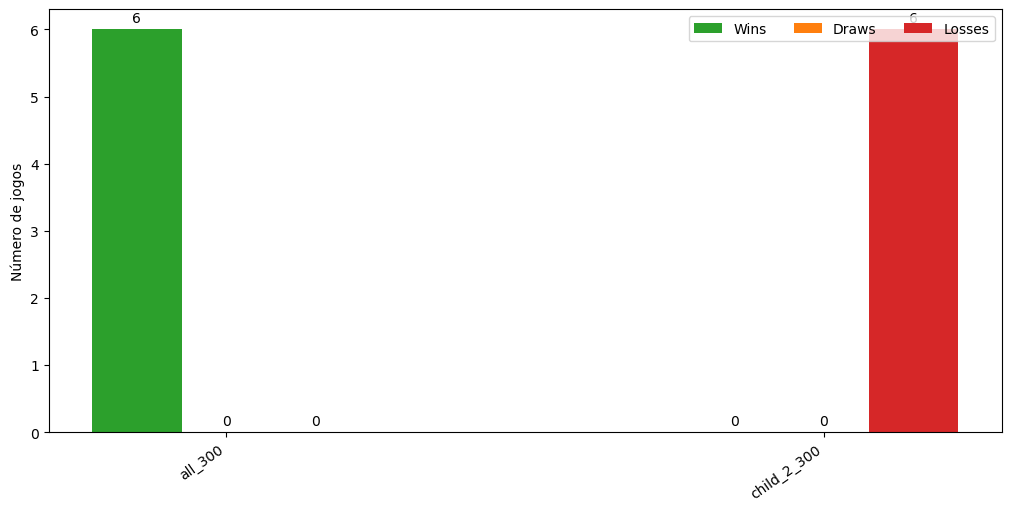

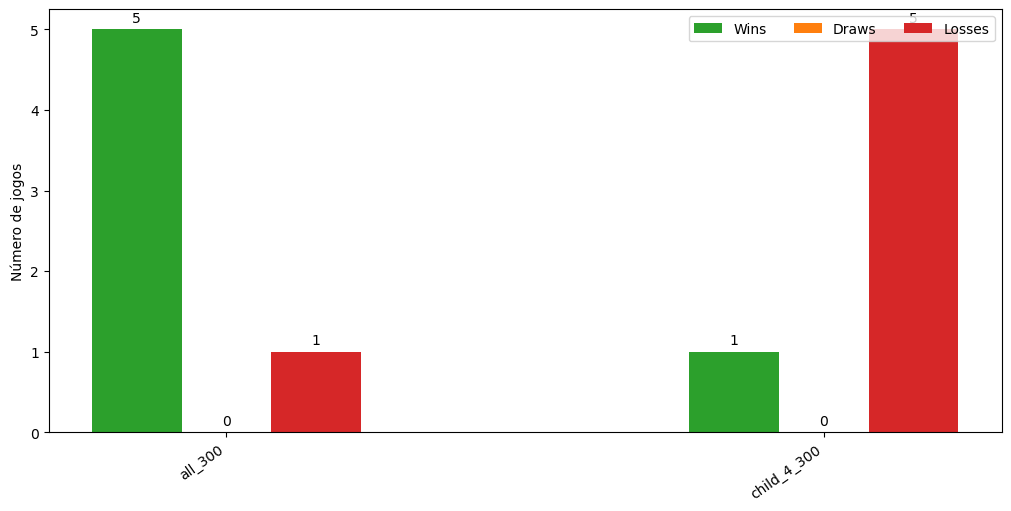

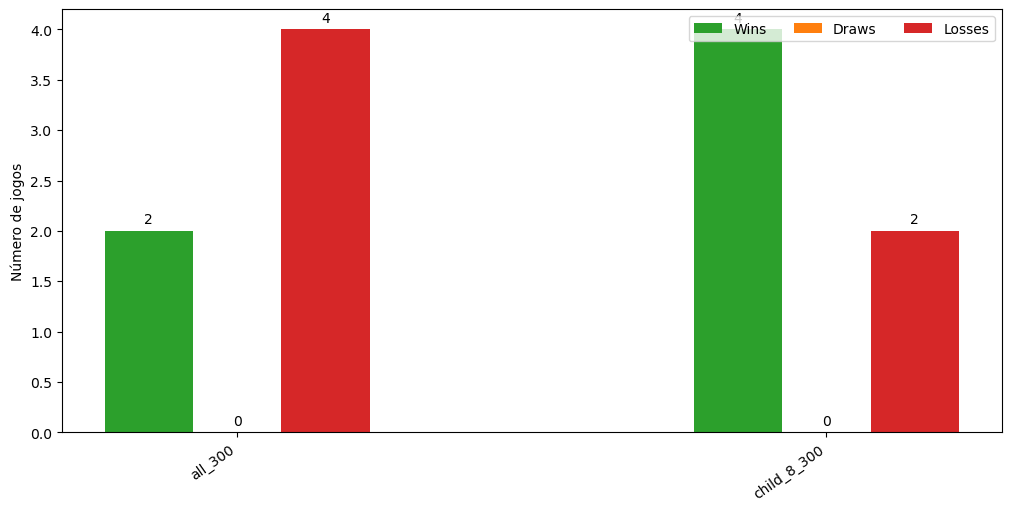

In [33]:
plot_bars_for_each_var(stats_2, "")
plot_bars_for_each_var(stats_4, "")
plot_bars_for_each_var(stats_8, "")

In [5]:
iter_variants = [
    ("all_100", MCTS(max_iter=100)),
    ("child_8_100", MCTS(child_limit=8, max_iter=100)),
    ("all_300", MCTS(max_iter=300)),
    ("child_8_300", MCTS(child_limit=8, max_iter=300)),
    ("all_500", MCTS(max_iter=500)),
    ("child_8_500", MCTS(child_limit=8, max_iter=500)),
] 

In [7]:
stats_iter_100 = variants_stats([iter_variants[0], iter_variants[1]], n_games=10)
stats_iter_300 = variants_stats([iter_variants[2], iter_variants[3]], n_games=10)
stats_iter_500 = variants_stats([iter_variants[4], iter_variants[5]], n_games=10)

In [8]:
stats_iter_100

{'all_100': {'wins': 9,
  'draws': 0,
  'losses': 11,
  'avg_time_sum': 1.077801831441603,
  'win_rate': 0.45,
  'draw_rate': 0.0,
  'loss_rate': 0.55,
  'avg_time_per_move': 0.05389009157208015},
 'child_8_100': {'wins': 11,
  'draws': 0,
  'losses': 9,
  'avg_time_sum': 1.1141086861118317,
  'win_rate': 0.55,
  'draw_rate': 0.0,
  'loss_rate': 0.45,
  'avg_time_per_move': 0.055705434305591585}}

plot_bars_for_each_var(stats_iter_100, "")
plot_bars_for_each_var(stats_iter_300, "")
plot_bars_for_each_var(stats_iter_500, "")

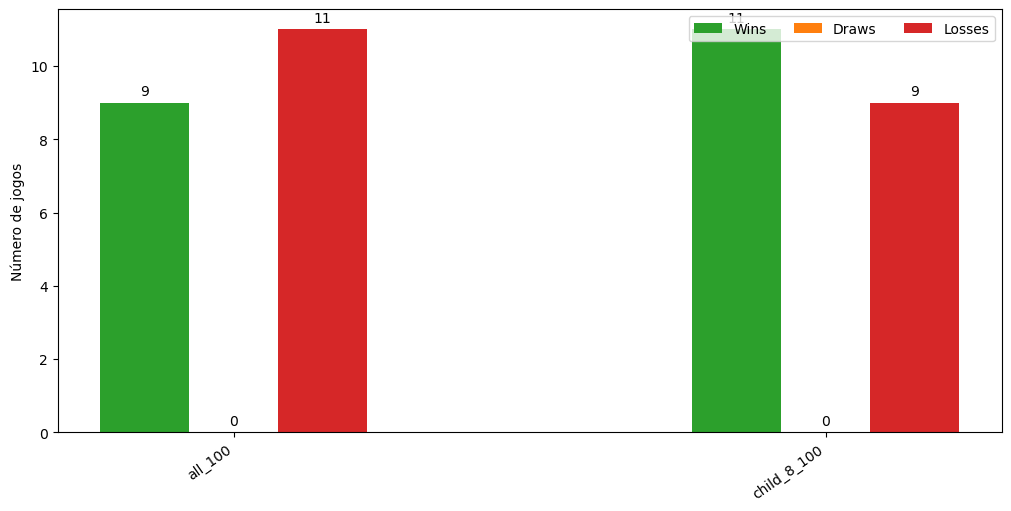

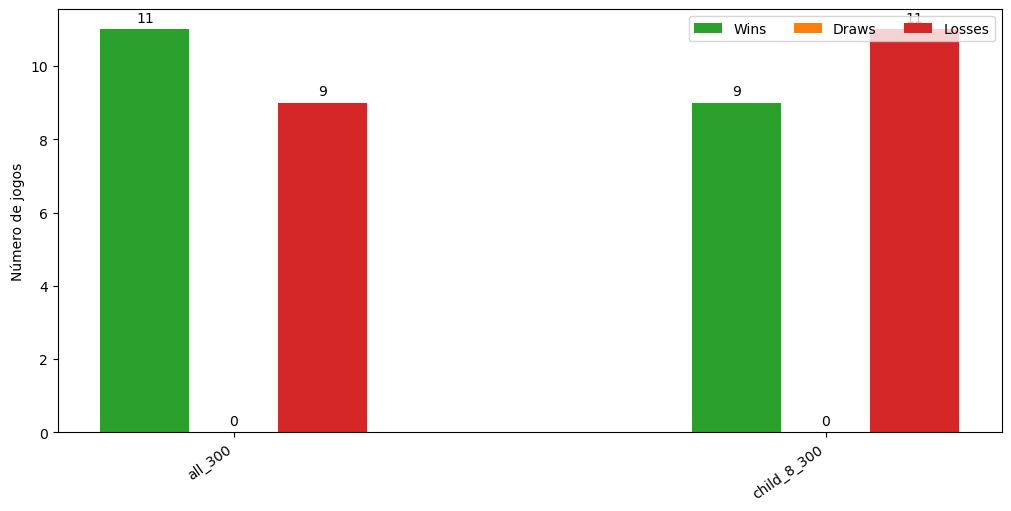

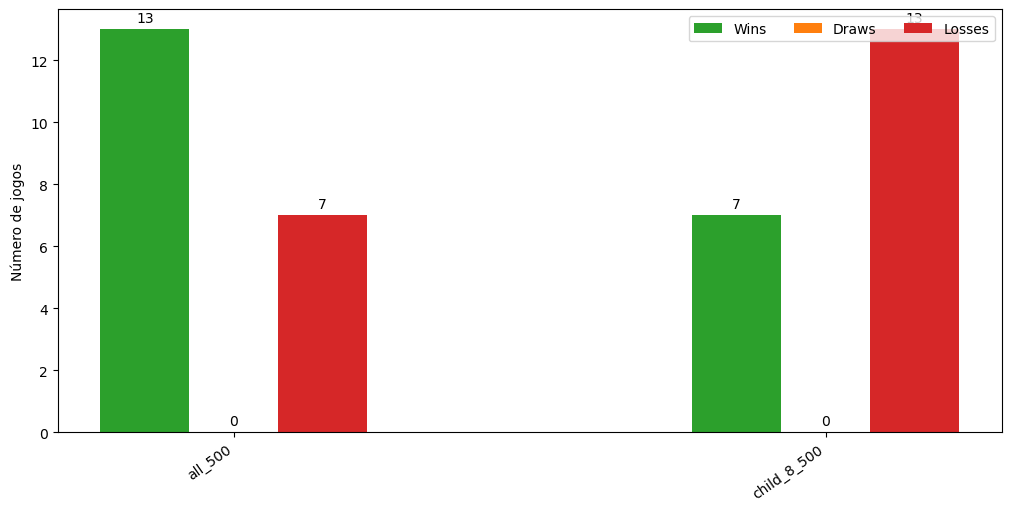

In [9]:
plot_bars_for_each_var(stats_iter_100, "")
plot_bars_for_each_var(stats_iter_300, "")
plot_bars_for_each_var(stats_iter_500, "")

In [6]:
#ir buscar os moves possiveis em vez dos estados seria mais rapido principalmente na simualcao do mcts...
heuristic_variants = [
("mcts_simplest", MCTS(child_limit=8)),
("heuristic_win", MCTS(child_limit=8,heuristic_win=True)),
("heuristic_block_win", MCTS(child_limit=8,heuristic_block_win=True)),
("win_and_block_win", MCTS(child_limit=8,heuristic_win=True, heuristic_block_win=True)),
("tree", MCTS(child_limit=8,save_tree=True)),
("full" , MCTS(child_limit=8,heuristic_win=True, heuristic_block_win=True, save_tree=True))
]

In [ ]:
#para os que teêm child limit nao deve importar... dps ve-se

stats_win= variants_stats([heuristic_variants[0], heuristic_variants[1]], n_games=1)
stats_block = variants_stats([heuristic_variants[0], heuristic_variants[2]], n_games=1)
stats_win_and_block = variants_stats([heuristic_variants[0], heuristic_variants[3]], n_games=1)
stats_tree = variants_stats([heuristic_variants[0], heuristic_variants[4]], n_games=1)
stats_full = variants_stats([heuristic_variants[0], heuristic_variants[5]], n_games=1)

In [15]:
stats_block = variants_stats([heuristic_variants[0], heuristic_variants[2]], n_games=1)

In [20]:
print(stats_win["heuristic_win"]["avg_time_per_move"])
print(stats_block["heuristic_block_win"]["avg_time_per_move"])
print(stats_win_and_block["win_and_block_win"]["avg_time_per_move"])
print(stats_tree["tree"]["avg_time_per_move"])
print(stats_full["full"]["avg_time_per_move"])

0.06978201561968234
4.555491317314019
2.088952384740214
0.15139707374934613
2.578754839131891


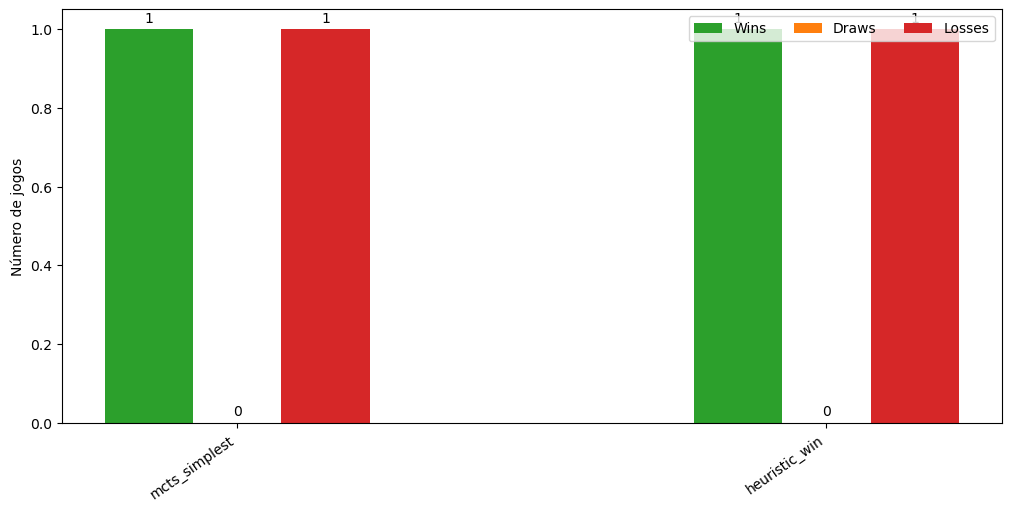

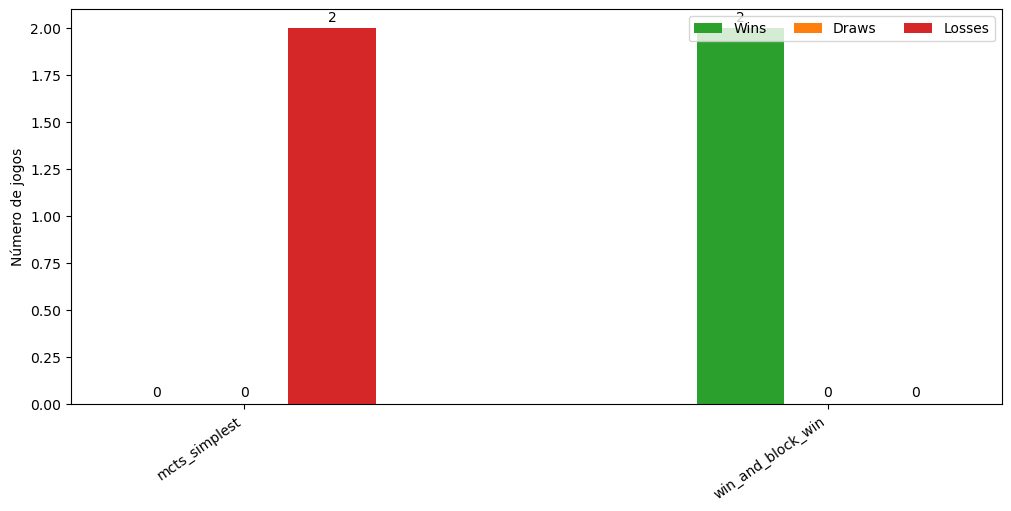

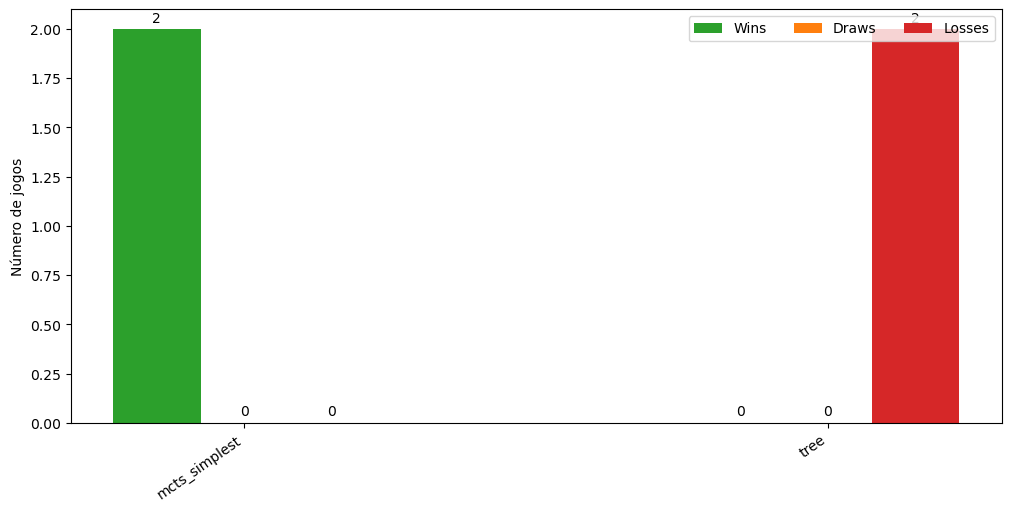

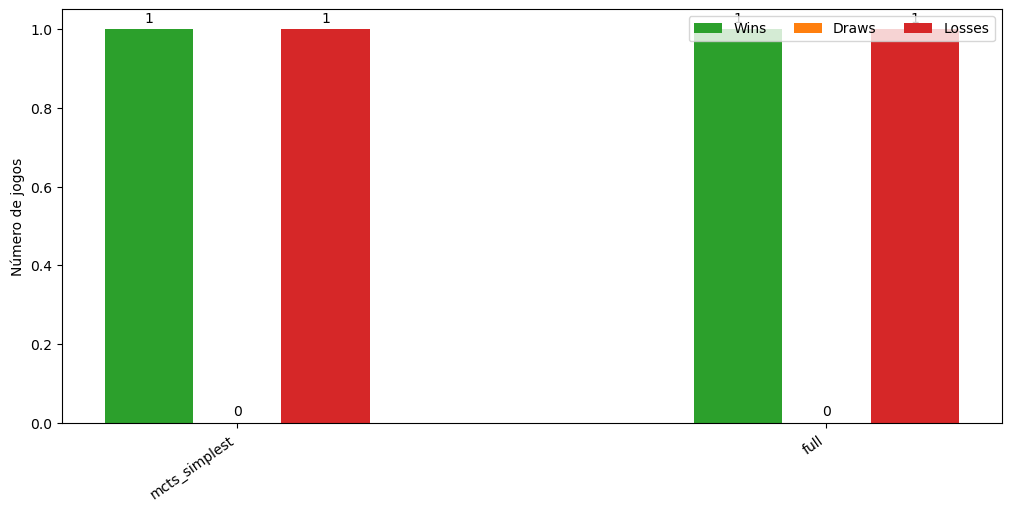

In [14]:
plot_bars_for_each_var(stats_win, "")
#plot_bars_for_each_var(stats_block, "")
plot_bars_for_each_var(stats_win_and_block, "")
plot_bars_for_each_var(stats_tree, "")
plot_bars_for_each_var(stats_full, "")

In [ ]:
#tbm pensei que se podia plotar a taxa de vitorais em funcao do tempo para estas 

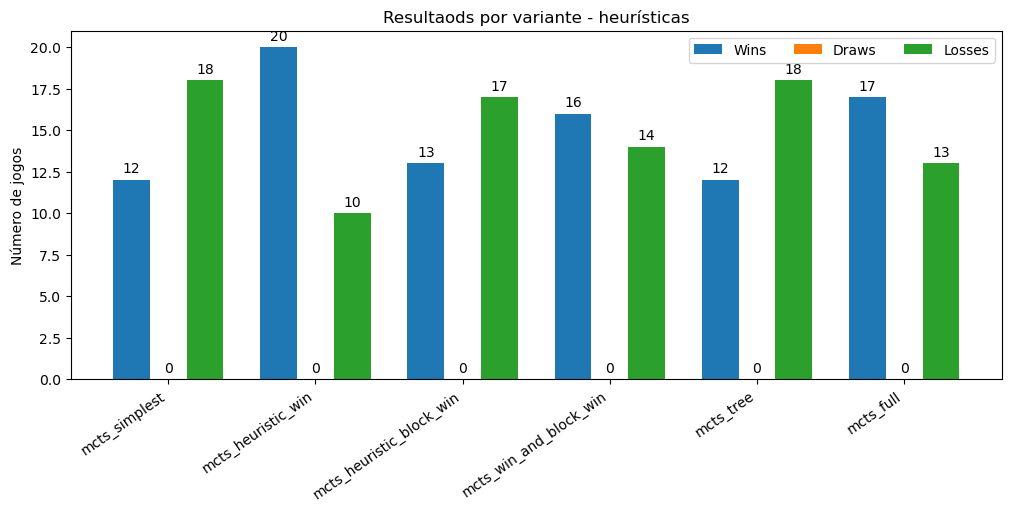

In [ ]:
#resquícios de algo que teve a correr durante 220 mins
plot_bars_for_each_var(heuristic_stats, "Resultaods por variante - heurísticas")